# LSTM ile Remaining Useful Life (RUL) Tahmini

## 1. Veri Hazırlama ve İnceleme

Bu çalışmada N-CMAPSS DS02 veri seti kullanılarak LSTM tabanlı bir RUL tahmin modeli geliştirilecektir.

Random Forest modelinden farklı olarak, LSTM modeline istatistiksel olarak özetlenmiş özellikler yerine zaman sırası korunmuş sensör ölçümleri verilecektir.

Her örnek 256 zaman adımı ve 18 değişkenden oluşmaktadır. Modelin amacı, bu ölçümlerden motorun kalan faydalı ömrünü (RUL) tahmin etmektir.

Model performansı, Random Forest ile aynı motor bazlı cross-validation ayrımları kullanılarak değerlendirilecektir.


5270 pencere



Her pencerede 256 zaman adımı



Her zaman adımında 18 özellik



Her pencere için bir gerçek RUL değeri

5 train motoru 1 validate motoru


In [4]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

# Proje ana klasörünü bul
current_dir = Path.cwd().resolve()

if (current_dir / "preprocessing").is_dir():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "preprocessing").is_dir():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Proje ana klasörü bulunamadı."
    )

# Ortak modüllere erişim
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from preprocessing.data_loader import (
    NCmapssDataLoader,
    load_window_metadata,
    load_feature_names
)

# Pencere bilgilerini yükle
windows = load_window_metadata()
feature_names = load_feature_names()

print("Toplam pencere sayısı:", len(windows))
print("Özellik sayısı:", len(feature_names))

Toplam pencere sayısı: 5270
Özellik sayısı: 18


In [5]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

# Proje ana klasörünü bul
current_dir = Path.cwd().resolve()

if (current_dir / "preprocessing").is_dir():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "preprocessing").is_dir():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Proje ana klasörü bulunamadı."
    )

# Ortak modüllere erişim
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from preprocessing.data_loader import (
    NCmapssDataLoader,
    load_window_metadata,
    load_feature_names
)

# Pencere bilgilerini yükle
windows = load_window_metadata()
feature_names = load_feature_names()

print("Toplam pencere sayısı:", len(windows))
print("Özellik sayısı:", len(feature_names))

Toplam pencere sayısı: 5270
Özellik sayısı: 18


In [6]:
# İlk pencereyi seç
first_window = windows[0]

# Pencerenin gerçek ölçümlerini yükle
with NCmapssDataLoader() as loader:
    X_window, y_rul = loader.load_window(first_window)

print("Pencere boyutu:", X_window.shape)
print("Gerçek RUL:", y_rul)


df_window = pd.DataFrame(
    X_window,
    columns=feature_names
)

display(df_window)
print(df_window.shape)

Pencere boyutu: (256, 18)
Gerçek RUL: 74.0


,alt,Mach,TRA,T2,T24,T30,T48,T50,P15,P2,P21,P24,Ps30,P40,P50,Nf,Nc,Wf
0,10005.0,0.448497,76.903748,502.420929,600.148010,1438.498169,1818.027710,1228.129883,15.806267,11.577097,16.046970,20.126623,331.293671,336.631836,12.629360,2160.926514,8591.373047,3.855337
1,10013.0,0.447741,76.903748,502.326111,600.055908,1438.350220,1817.682617,1227.879150,15.795477,11.568235,16.036016,20.113218,331.109863,336.446747,12.623033,2160.909424,8590.972656,3.852319
2,10017.0,0.448938,77.079529,502.416077,600.210754,1439.109131,1820.020630,1229.422485,15.807747,11.574866,16.048473,20.130957,331.753174,337.082489,12.637951,2161.819092,8593.032227,3.866201
3,10024.0,0.449883,77.079529,502.469879,600.369690,1439.240234,1819.188354,1228.538696,15.816360,11.578198,16.057219,20.146717,331.819122,337.162842,12.631510,2162.768555,8593.781250,3.863328
4,10031.0,0.449379,77.079529,502.401276,600.298218,1439.063965,1818.963501,1228.389038,15.807512,11.571593,16.048237,20.135889,331.626007,336.966949,12.624871,2162.619629,8593.219727,3.860818
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,11276.0,0.511308,77.782646,503.475525,602.010620,1439.643677,1817.572021,1221.400757,15.658207,11.470847,15.896656,20.010462,327.122467,332.422638,12.186440,2171.427490,8595.296875,3.800925
252,11283.0,0.511749,77.782646,503.491760,602.007385,1439.595337,1817.734375,1221.542603,15.657008,11.471131,15.895440,20.008410,327.064789,332.361298,12.184427,2171.221191,8595.042969,3.801044
253,11293.0,0.511749,77.782646,503.454559,601.972778,1439.538086,1817.536743,1221.368896,15.651494,11.466644,15.889841,20.001717,326.966034,332.262238,12.179761,2171.266602,8594.910156,3.799301
254,11302.0,0.511686,77.782646,503.413239,601.923035,1439.423462,1817.399658,1221.274780,15.645083,11.461978,15.883333,19.993502,326.827789,332.121735,12.174794,2171.160156,8594.541016,3.797553


(256, 18)


In [7]:
from features.dl_sequences import build_sequences

X_lstm, y_lstm = build_sequences(windows)

print("LSTM X boyutu:", X_lstm.shape)
print("LSTM y boyutu:", y_lstm.shape)

print("İlk pencerenin gerçek RUL:", y_lstm[0])

İşlenen pencere: 500/5270
İşlenen pencere: 1000/5270
İşlenen pencere: 1500/5270
İşlenen pencere: 2000/5270
İşlenen pencere: 2500/5270
İşlenen pencere: 3000/5270
İşlenen pencere: 3500/5270
İşlenen pencere: 4000/5270
İşlenen pencere: 4500/5270
İşlenen pencere: 5000/5270
LSTM X boyutu: (5270, 256, 18)
LSTM y boyutu: (5270,)
İlk pencerenin gerçek RUL: 74.0


In [8]:
import json
from pathlib import Path

# Fold dosyasını yükle
fold_path = Path("../processed/split_folds.json")

with open(fold_path, "r") as f:
    folds = json.load(f)

print("Fold sayısı:", len(folds["folds"]))
print("İlk fold:", folds["folds"][0])

# Random Forest ile aynı fold'u kullanalım
fold = folds["folds"][0]

train_units = fold["train_units"]
val_units = fold["validation_units"]

# Her pencerenin hangi motora ait olduğunu bul
window_units = np.array([w.unit for w in windows])

# Motor bazlı indeksleri oluştur
train_mask = np.isin(window_units, train_units)
val_mask = np.isin(window_units, val_units)

# LSTM verilerini ayır
X_train_lstm = X_lstm[train_mask]
X_val_lstm = X_lstm[val_mask]

y_train_lstm = y_lstm[train_mask]
y_val_lstm = y_lstm[val_mask]

print("Eğitim X:", X_train_lstm.shape)
print("Doğrulama X:", X_val_lstm.shape)

print("Eğitim motorları:", train_units)
print("Doğrulama motorları:", val_units)

Fold sayısı: 6
İlk fold: {'fold': 1, 'train_units': [5, 10, 16, 18, 20], 'validation_units': [2]}
Eğitim X: (4416, 256, 18)
Doğrulama X: (854, 256, 18)
Eğitim motorları: [5, 10, 16, 18, 20]
Doğrulama motorları: [2]


In [9]:
from sklearn.preprocessing import StandardScaler

# Ölçeklendiriciyi oluştur
scaler = StandardScaler()

# Üç boyutlu veriyi geçici olarak iki boyuta indir
n_train, timesteps, n_features = X_train_lstm.shape
n_val = X_val_lstm.shape[0]

X_train_2d = X_train_lstm.reshape(-1, n_features)
X_val_2d = X_val_lstm.reshape(-1, n_features)

# Yalnızca eğitim verisinden öğren
X_train_scaled = scaler.fit_transform(X_train_2d)

# Doğrulama verisine aynı dönüşümü uygula
X_val_scaled = scaler.transform(X_val_2d)

# LSTM için yeniden üç boyuta dönüştür
X_train_scaled = X_train_scaled.reshape(
    n_train, timesteps, n_features
).astype("float32")

X_val_scaled = X_val_scaled.reshape(
    n_val, timesteps, n_features
).astype("float32")

print("Eğitim:", X_train_scaled.shape)
print("Doğrulama:", X_val_scaled.shape)

Eğitim: (4416, 256, 18)
Doğrulama: (854, 256, 18)


In [10]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

# Tekrarlanabilir sonuçlar için
tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(256, 18)),

    LSTM(64),

    Dropout(0.2),

    Dense(32, activation="relu"),

    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        21,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,361 (91.25 KB)

 Trainable params: 23,361 (91.25 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train_lstm,
    validation_data=(X_val_scaled, y_val_lstm),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - loss: 1247.0118 - mae: 28.8951 - val_loss: 474.9316 - val_mae: 18.7722
Epoch 2/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 516.9868 - mae: 19.4269 - val_loss: 463.7893 - val_mae: 18.6874
Epoch 3/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - loss: 514.8785 - mae: 19.3710 - val_loss: 463.3235 - val_mae: 18.6818
Epoch 4/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 511.7922 - mae: 19.2928 - val_loss: 462.2522 - val_mae: 18.6583
Epoch 5/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - loss: 512.4324 - mae: 19.3318 - val_loss: 460.9485 - val_mae: 18.6352
Epoch 6/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 509.3712 - mae: 19.2534 - val_loss: 457.6058 - val_mae: 18.5693
Epoch 7/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - loss: 503.7037 - mae: 19.1819 - val_loss: 449.9629 - val_mae: 18.4073
Epoch 8/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - loss: 490.0025 - mae: 18.9173 - val_loss: 422.2740 - val_mae: 17.7842
Epoch 9/30
69/6

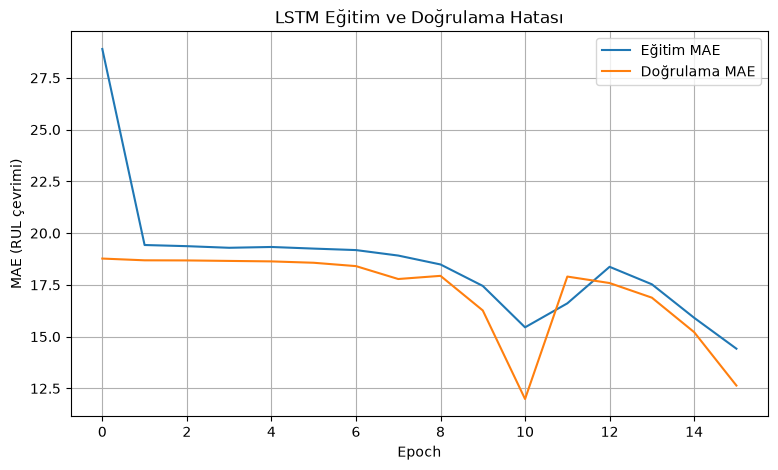

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(history.history["mae"], label="Eğitim MAE")
plt.plot(history.history["val_mae"], label="Doğrulama MAE")

plt.xlabel("Epoch")
plt.ylabel("MAE (RUL çevrimi)")
plt.title("LSTM Eğitim ve Doğrulama Hatası")
plt.legend()
plt.grid(True)

plt.show()

In [14]:
 
# Her pencerenin ait olduğu motoru kaydet
engine_ids = np.array([
    window.unit for window in windows
])

print("Motor ID dizisinin boyutu:", engine_ids.shape)
print("Motorlar:", np.unique(engine_ids))

# Pencere sayılarının eşleştiğini doğrula
assert len(engine_ids) == len(X_lstm)


Motor ID dizisinin boyutu: (5270,)
Motorlar: [ 2  5 10 16 18 20]


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense

fold_histories = {}

for fold in folds["folds"]:
    lstm_predictions = {}
    fold_id = fold["fold"]
    train_units = fold["train_units"]
    val_units = fold["validation_units"]

    print(f"\nFold {fold_id} - Doğrulama motoru: {val_units}")

    # Motor bazlı ayrım
    train_mask = np.isin(engine_ids, train_units)
    val_mask = np.isin(engine_ids, val_units)

    X_train_fold = X_lstm[train_mask]
    X_val_fold = X_lstm[val_mask]

    y_train_fold = y_lstm[train_mask]
    y_val_fold = y_lstm[val_mask]

    # Ölçeklendirme: yalnızca eğitim verisinden öğren
    scaler = StandardScaler()

    n_features = X_train_fold.shape[2]

    X_train_fold = scaler.fit_transform(
        X_train_fold.reshape(-1, n_features)
    ).reshape(X_train_fold.shape).astype("float32")

    X_val_fold = scaler.transform(
        X_val_fold.reshape(-1, n_features)
    ).reshape(X_val_fold.shape).astype("float32")

    # Her fold için yeni model
    model = Sequential([
        Input(shape=(256, n_features)),
        LSTM(64),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    history = model.fit(
        X_train_fold,
        y_train_fold,
        validation_data=(X_val_fold, y_val_fold),
        epochs=30,
        batch_size=64,
        verbose=0
    )

    fold_histories[val_units[0]] = history.history

    print(f"Motor {val_units[0]} tamamlandı.")



Fold 1 - Doğrulama motoru: [2]
Motor 2 tamamlandı.

Fold 2 - Doğrulama motoru: [5]
Motor 5 tamamlandı.

Fold 3 - Doğrulama motoru: [10]
Motor 10 tamamlandı.

Fold 4 - Doğrulama motoru: [16]
Motor 16 tamamlandı.

Fold 5 - Doğrulama motoru: [18]
Motor 18 tamamlandı.

Fold 6 - Doğrulama motoru: [20]
Motor 20 tamamlandı.


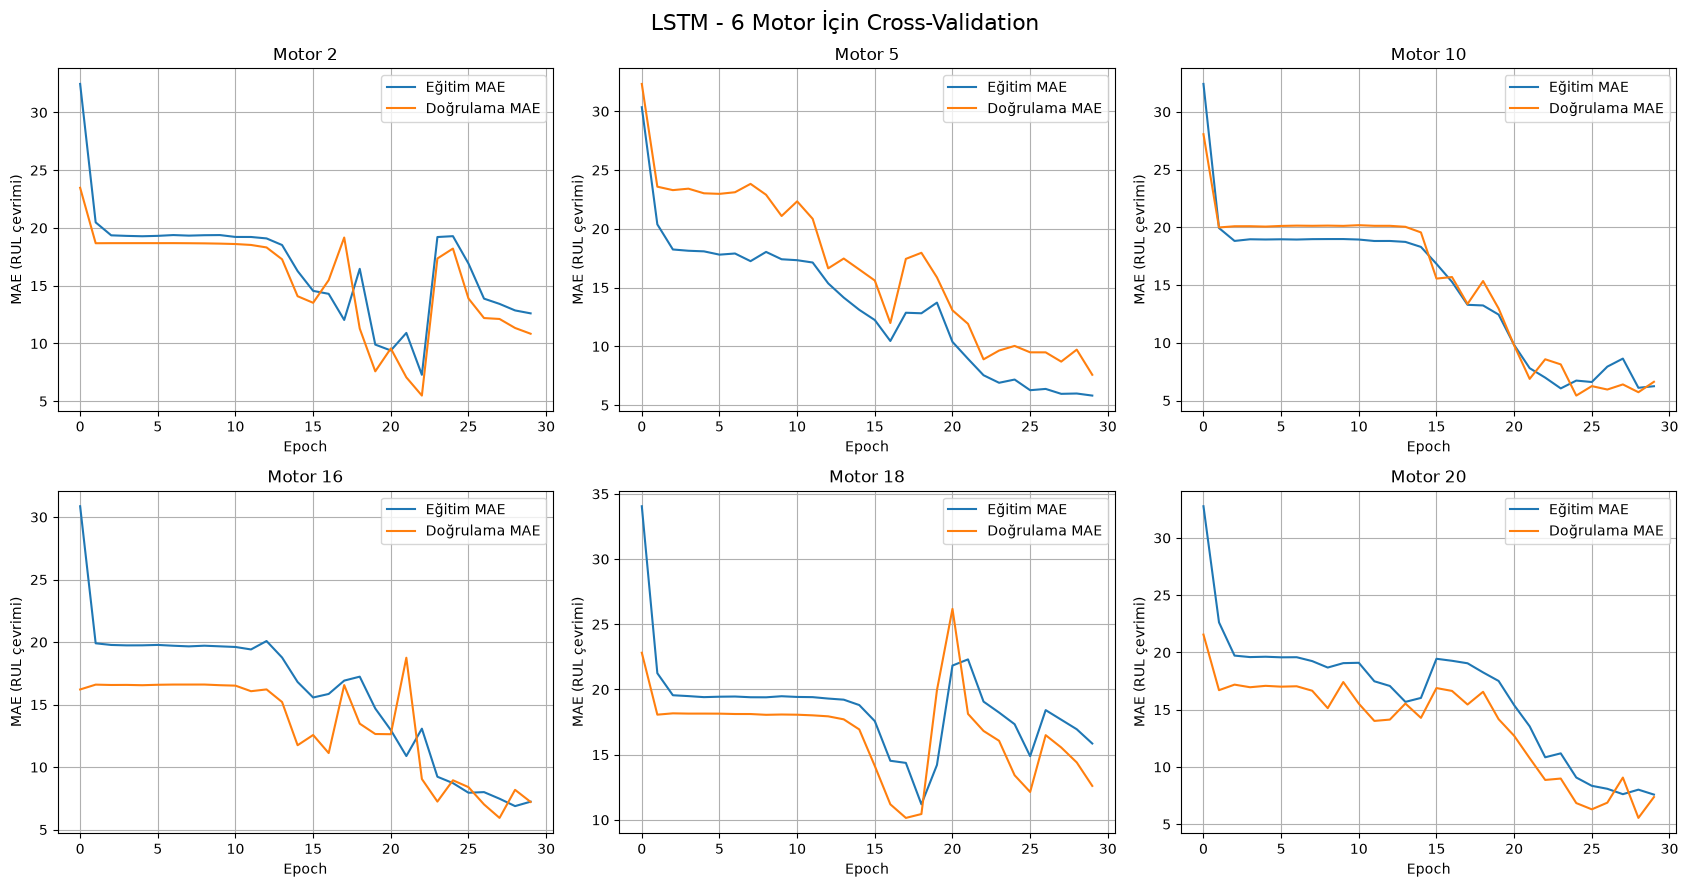

In [16]:

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for ax, (motor, history) in zip(axes.flat, fold_histories.items()):

    ax.plot(history["mae"], label="Eğitim MAE")
    ax.plot(history["val_mae"], label="Doğrulama MAE")

    ax.set_title(f"Motor {motor}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MAE (RUL çevrimi)")
    ax.legend()
    ax.grid(True)

plt.suptitle("LSTM - 6 Motor İçin Cross-Validation", fontsize=16)
plt.tight_layout()
plt.show()


In [17]:

import pandas as pd

results = []

for motor, history in fold_histories.items():
    results.append({
        "Motor": motor,
        "Eğitim MAE": history["mae"][-1],
        "Doğrulama MAE": history["val_mae"][-1],
        "En İyi Doğrulama MAE": min(history["val_mae"]),
        "En İyi Epoch": np.argmin(history["val_mae"]) + 1
    })

df_results = pd.DataFrame(results)

display(df_results.round(2))

print(
    "Ortalama doğrulama MAE:",
    round(df_results["Doğrulama MAE"].mean(), 2)
)


,Motor,Eğitim MAE,Doğrulama MAE,En İyi Doğrulama MAE,En İyi Epoch
0,2,12.61,10.84,5.49,23
1,5,5.81,7.58,7.58,30
2,10,6.24,6.62,5.43,25
3,16,7.24,7.22,5.94,28
4,18,15.86,12.61,10.15,18
5,20,7.58,7.37,5.55,29


Ortalama doğrulama MAE: 8.71
